# Lab 04 · Part 1 — Zero-shot and few-shot prompting

**Application:** IT helpdesk ticket triage. A ticket comes in as free text
("my outlook keeps asking for my password") and has to be routed to one of five
queues: `account_access`, `network`, `hardware`, `software`, `email`.

**Model:** `SmolLM2-135M-Instruct`, small enough to run (and later fine-tune)
on a laptop CPU.

This lab asks one question: *how do you adapt a pretrained model to a task you
care about, and what does each option cost?* In this first notebook the model's
weights never change. We only change the prompt:

* **zero-shot** — describe the task, give no examples
* **few-shot** — describe the task and paste `k` labelled tickets per category into the prompt

Part 2 then changes the weights (full fine-tuning, LoRA, QLoRA) and Part 3
puts everything side by side.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, ".")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

from tickets import (LABELS, load_tickets, load_general_sentences, sample_per_class,
                     zero_shot_prompt, few_shot_prompt)
from model_utils import (load_model, label_token_ids, evaluate, general_perplexity,
                         prompt_tokens)

RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

## The data

200 tickets I wrote by hand (see `data/make_tickets.py`), 40 per category. For
each category the first 20 are the **train pool** and the last 20 are the
**test set**, so the test set is 100 tickets, balanced, and never used for
examples or training. Some are deliberately ambiguous (a VPN *login* problem is
account access, a VPN *timeout* is network).

In [2]:
train_df, test_df = load_tickets()
print(len(train_df), "train pool /", len(test_df), "test")
train_df.groupby("label").head(2)[["label", "text"]].reset_index(drop=True)

100 train pool / 100 test


,label,text
0,account_access,I forgot my password and the reset email never shows up.
1,account_access,My account got locked after I typed the wrong password three times.
2,network,The wifi in conference room B drops every few minutes.
3,network,"I can't connect to the VPN from home, it times out at 90 percent."
4,hardware,My laptop screen is flickering and has a vertical line down the middle.
5,hardware,"The keyboard is missing keys, a few of them popped off."
6,software,Excel crashes every time I open the budget spreadsheet.
7,software,Please install Python 3.11 and VS Code on my workstation.
8,email,My Outlook inbox isn't receiving new messages since this morning.
9,email,"I can send emails but nobody gets them, no bounce message either."


## How the model's answer is read

A decoder model generates free text, which is awkward to score. Instead I
end every prompt with `Category:` and look at the model's next-token scores for
the first token of each of the five category names. The highest one is the
prediction. This is the same read-out in every notebook, so zero-shot, few-shot
and the fine-tuned models are all scored the same way.

In [3]:
model, tokenizer = load_model()
label_ids = label_token_ids(tokenizer)
print([tokenizer.decode([i]) for i in label_ids])
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters")

[' account', ' network', ' hardware', ' software', ' email']
134.5M parameters


## Zero-shot

In [4]:
test_prompts = [zero_shot_prompt(t) for t in test_df["text"]]
test_labels = test_df["label"].tolist()

print(test_prompts[0])

You are an IT helpdesk assistant. Read the support ticket and answer with exactly one category.
Categories: account_access, network, hardware, software, email

Ticket: Please grant my intern read access to the analytics dashboard.
Category:


zero-shot  accuracy 0.440   macro-F1 0.412   ~57 prompt tokens   0.01s/ticket


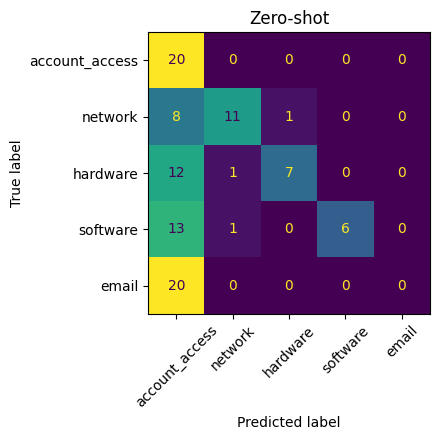

In [5]:
zs = evaluate(model, tokenizer, test_prompts, test_labels, label_ids)
zs_tokens = np.mean([prompt_tokens(tokenizer, p) for p in test_prompts])
print(f"zero-shot  accuracy {zs['accuracy']:.3f}   macro-F1 {zs['macro_f1']:.3f}   "
      f"~{zs_tokens:.0f} prompt tokens   {zs['sec_per_ticket']:.2f}s/ticket")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions([LABELS.index(l) for l in test_labels], zs["preds"],
                                        display_labels=LABELS, xticks_rotation=45,
                                        ax=ax, colorbar=False)
ax.set_title("Zero-shot")
plt.tight_layout()
plt.savefig(RESULTS / "zero_shot_confusion.png", dpi=120)
plt.show()

## Few-shot

Now `k` labelled tickets per category (so `5k` examples) go in front of the
question. The examples come from the train pool. Which `k` tickets get picked
matters a lot for small models, so each `k` is run with 3 different random picks
(seeds 0-2).

In [6]:
shots = sample_per_class(train_df, 1, seed=0)
print(few_shot_prompt(test_df["text"][0], shots))

You are an IT helpdesk assistant. Read the support ticket and answer with exactly one category.
Categories: account_access, network, hardware, software, email

Ticket: My login works on the website but not in the mobile app.
Category: account_access

Ticket: The keyboard is missing keys, a few of them popped off.
Category: hardware

Ticket: The printer network share isn't visible from my PC, but it is on others.
Category: network

Ticket: Recurring meeting emails are duplicated in my inbox.
Category: email

Ticket: PowerPoint is stuck on not responding when I add a video.
Category: software

Ticket: Please grant my intern read access to the analytics dashboard.
Category:


In [7]:
rows = []
for k in [1, 2, 4]:
    for seed in [0, 1, 2]:
        shots = sample_per_class(train_df, k, seed)
        prompts = [few_shot_prompt(t, shots) for t in test_df["text"]]
        r = evaluate(model, tokenizer, prompts, test_labels, label_ids)
        rows.append({"k": k, "seed": seed, "accuracy": r["accuracy"], "macro_f1": r["macro_f1"],
                     "prompt_tokens": np.mean([prompt_tokens(tokenizer, p) for p in prompts]),
                     "sec_per_ticket": r["sec_per_ticket"]})
        print(f"k={k} seed={seed}  acc {r['accuracy']:.3f}  F1 {r['macro_f1']:.3f}  "
              f"{rows[-1]['prompt_tokens']:.0f} tokens  {r['sec_per_ticket']:.2f}s/ticket")

few = pd.DataFrame(rows)
summary = few.groupby("k").agg(acc_mean=("accuracy", "mean"), acc_std=("accuracy", "std"),
                               f1_mean=("macro_f1", "mean"), prompt_tokens=("prompt_tokens", "mean"),
                               sec_per_ticket=("sec_per_ticket", "mean")).round(3)
summary

k=1 seed=0  acc 0.560  F1 0.487  170 tokens  0.02s/ticket
k=1 seed=1  acc 0.370  F1 0.252  187 tokens  0.02s/ticket
k=1 seed=2  acc 0.450  F1 0.407  177 tokens  0.02s/ticket
k=2 seed=0  acc 0.780  F1 0.755  290 tokens  0.03s/ticket
k=2 seed=1  acc 0.670  F1 0.644  296 tokens  0.03s/ticket
k=2 seed=2  acc 0.440  F1 0.359  285 tokens  0.03s/ticket
k=4 seed=0  acc 0.280  F1 0.212  499 tokens  0.05s/ticket
k=4 seed=1  acc 0.420  F1 0.384  529 tokens  0.05s/ticket
k=4 seed=2  acc 0.660  F1 0.623  510 tokens  0.05s/ticket


,acc_mean,acc_std,f1_mean,prompt_tokens,sec_per_ticket
k,,,,,
1,0.460,0.095,0.382,177.910,0.016
2,0.630,0.173,0.586,290.243,0.026
4,0.453,0.192,0.406,512.577,0.052


## Does prompting change what the model is?

It shouldn't: the weights are untouched. As a baseline for Part 2, here is the
model's perplexity on 20 plain English sentences (`data/general_sentences.txt`).
After fine-tuning we check whether this number moves.

In [8]:
base_ppl = general_perplexity(model, tokenizer, load_general_sentences())
print(f"base model perplexity on general text: {base_ppl:.2f}")

json.dump({
    "zero_shot": {"accuracy": zs["accuracy"], "macro_f1": zs["macro_f1"],
                  "sec_per_ticket": zs["sec_per_ticket"], "prompt_tokens": zs_tokens,
                  "preds": zs["preds"]},
    "few_shot": rows,
    "base_general_ppl": base_ppl,
}, open(RESULTS / "prompting.json", "w"), indent=1)

base model perplexity on general text: 32.27


### Where does zero-shot go wrong?

In [9]:
wrong = test_df.assign(pred=[LABELS[i] for i in zs["preds"]])
wrong = wrong[wrong["label"] != wrong["pred"]][["text", "label", "pred"]]
print(f"{len(wrong)} of {len(test_df)} wrong")
wrong.head(12).reset_index(drop=True)

56 of 100 wrong


,text,label,pred
0,"My IP address conflicts with another device, windows shows a warning.",network,account_access
1,Can't SSH into the build server from outside the office anymore.,network,account_access
2,Switch in the server closet has a blinking amber light and half the floor is offline.,network,hardware
3,The proxy keeps asking for credentials over and over and then fails.,network,account_access
4,My home router is fine but only the company laptop can't get online.,network,account_access
5,Our VoIP phones are choppy and the audio cuts out mid-sentence.,network,account_access
6,Can you check the port forwarding on the router for the security camera?,network,account_access
7,Wifi is great at my desk but the signal is basically zero in the break room.,network,account_access
8,I can browse the internet but internal sites say server not found.,network,account_access
9,"My laptop won't charge, the light on the adapter is off.",hardware,account_access


## What I saw

* **Zero-shot is barely better than guessing a favourite.** 44% accuracy (chance is 20%).
  The model answered `account_access` for 73 of the 100 tickets (the first category
  in the prompt) and never once said `email`. Network tickets with words like
  "credentials" or "VPN" get pulled into `account_access`.
* **Few-shot helps, but unreliably.** Mean accuracy 46% / 63% / 45% for k = 1 / 2 / 4,
  and the spread across the 3 example picks (std 0.10-0.19) is as big as the gains.
  The best single run (k=2, 78%) and the worst (k=4, 28%) differ by 50 points just from
  *which* tickets were pasted in.
* **More examples was not better.** k=4 means ~510 prompt tokens, and a 135M model
  seems to lose track of the question at that length. It is also 5x slower per ticket than
  zero-shot. I only ran 3 seeds, so I would not claim the dip at k=4 is exact, only that
  there is no reliable gain past k=2 for a model this small.
* Prompting leaves the weights alone, so general-text perplexity stays at 32.3.